# F4 · 01 · Análisis de P1 e integración de las fases

**Qué hace este notebook:** recorre el proyecto en orden, desde el entorno de F1 hasta el análisis de F4, y responde la pregunta P1: ¿gana más seguido la respuesta más larga o con más formato?
**Qué no hace:** probar que el largo o el formato *causen* la preferencia. El estudio es observacional, así que solo se habla de asociaciones.

El notebook no repite código de las fases anteriores: lo llama.

| Fase | Qué se usa | Dónde está |
|---|---|---|
| F1 | Entorno reproducible y registro de versiones | `requirements.txt`, `arena.env` |
| F2 | Carga del dato crudo y validación | `arena.profile`, `arena.validation` |
| F3 | Pipeline orientado a objetos (`pasos_f3()`) | `arena.transformadores`, `arena.pipeline` |
| F4 | Tasas de victoria, regresiones y gráficos | `arena.analisis`, `arena.plots` |

Las decisiones de interpretación están en cada sección, después de los resultados.

## 0. Entorno
**Qué hacemos:** registrar con qué versiones corre el notebook (F1: entorno reproducible).
**Por qué:** cualquiera debe poder repetir los resultados; las versiones y el commit quedan anotados.

In [3]:
from arena.env import environment_info

info = environment_info()
{k: v for k, v in info.items() if k != "dependencies"}

{'python': '3.12.10',
 'system': 'Windows 11',
 'interpreter': 'c:\\Users\\valen\\Documents\\Magister_Data_Science\\Sumativa_1\\lmarena-sumativa1\\.venv\\Scripts\\python.exe',
 'virtual_env': True,
 'seed': 42,
 'git': {'branch': 'feat/f4-posicion-ab',
  'commit': 'f3a3d05',
  'clean': 'False'}}

## 1. De los datos crudos al dataset limpio (F2 y F3)
**Qué hacemos:** cargar el dato crudo (sin las columnas de texto) y pasarlo por el pipeline orientado a objetos de F3, `pasos_f3()`.
**Por qué:** el análisis tiene que partir del mismo dataset que dejaron las fases anteriores, no de una copia armada a mano. Así el resultado se puede reproducir de punta a punta.

In [4]:
from arena.profile import load_raw
from arena.pipeline import Pipeline
from arena.transformadores import pasos_f3

raw = load_raw()
pipeline = Pipeline(pasos_f3())
df = pipeline.ajustar(raw).transformar(raw)
print(f"crudo: {raw.shape}  ->  limpio: {df.shape}")
print(pipeline)

crudo: (135634, 11)  ->  limpio: (135634, 53)
Pipeline(9 pasos, ajustado)


### 1.1 Validación del dataset limpio
**Qué hacemos:** correr el validador de F2 sobre el resultado del pipeline y revisar los nulos que quedan.
**Por qué:** antes de analizar hay que saber que el dato está íntegro: sin filas perdidas, sin duplicados y con los valores dentro de lo esperado.

In [5]:
from arena.validation import validate_dataset

informe = validate_dataset(df, expected_rows=len(raw))
informe.assert_ok()   # falla si hay algún chequeo crítico
informe.to_frame()

,status,check,detail
0,OK,required columns,all present
1,OK,no NA in key columns,none
2,OK,unique id,none duplicated
3,OK,winner in allowed set,all valid
4,OK,"evaluation_order integer in [1, 28]",0 out of range
5,OK,timestamp within 2025-04-17..2025-07-24,0 outside
6,OK,sum_assistant_a_tokens >= 0,0 negative
7,OK,sum_assistant_b_tokens >= 0,0 negative
8,OK,sum_user_tokens >= 0,0 negative
9,OK,context_a_tokens >= 0,0 negative


In [6]:
nulos = df.isna().sum()
nulos[nulos > 0].to_frame("nulos")

,nulos
cat_if_score,2


*Interpretación:* el validador no encuentra fallas críticas: se conservan las 135.634 filas, no hay `id` repetidos y los valores están dentro de lo esperado. El único aviso es el que ya conocíamos desde F2, 10 filas donde `model_a` y `model_b` son el mismo modelo. Quedan solo 2 nulos, los dos en `cat_if_score`. Vienen así en el dato original y no se imputan (decisión D-016). No afectan el análisis, que no usa esa columna.

## 2. Qué se compara
**Qué hacemos:** quedarnos con los votos que tienen ganador (A o B) y armar dos diferencias entre las respuestas: una de largo y otra de formato.
**Por qué:** la pregunta P1 es si gana más seguido la respuesta más larga o con más formato. Para eso hace falta que haya una ganadora.

- `y` vale 1 si ganó A y 0 si ganó B.
- `dif_tokens_log` es `tokens_log_a - tokens_log_b`: positiva si A es más larga.
- `dif_formato_log` es `log1p(format_a) - log1p(format_b)`: positiva si A tiene más encabezados, listas y negritas.

Los votos `tie` y `both_bad` no tienen ganadora y quedan fuera de las tasas de victoria. Lo que pasa con ellos se revisa en 2.1 (decisión P-01).

In [7]:
from arena.analisis import votos_decisivos

d = votos_decisivos(df)
resumen = df["winner"].value_counts().to_frame("votos")
resumen["%"] = (resumen["votos"] / len(df) * 100).round(2)
print(f"votos con ganadora: {len(d):,} de {len(df):,} ({len(d) / len(df):.1%})")
resumen

votos con ganadora: 98,348 de 135,634 (72.5%)


,votos,%
winner,,
model_b,49785,36.71
model_a,48563,35.80
tie,21532,15.88
both_bad,15754,11.62


### 2.1 ¿Qué pasa con los empates? (decisión P-01)
**Qué hacemos:** ver si los votos sin ganadora (`tie` y `both_bad`) se concentran cuando las dos respuestas tienen un largo parecido.
**Por qué:** si fuera así, dejarlos fuera no sería neutro: se perderían justo los casos en que el largo no distingue una respuesta de la otra.

In [8]:
from arena.analisis import tasa_empates_por_diferencia

empates = tasa_empates_por_diferencia(df)
empates.assign(tasa_pct=(empates["tasa"] * 100).round(1))[["n", "sin_ganador", "tasa_pct"]]

,n,sin_ganador,tasa_pct
"(-0.001, 0.1]",14835,4797,32.3
"(0.1, 0.25]",20320,6443,31.7
"(0.25, 0.5]",28292,8454,29.9
"(0.5, 1.0]",38150,10135,26.6
"(1.0, 2.0]",28401,6305,22.2
"(2.0, 10.0]",5636,1152,20.4


*Interpretación:* los votos sin ganadora son más frecuentes cuando las dos respuestas tienen un largo parecido: 32,3 % cuando la diferencia es de 0,1 o menos, y 20,4 % cuando una es mucho más larga. Tiene sentido: si una respuesta es claramente más larga, es menos común que la persona no se decida por ninguna. Esto responde la parte de P-01 que se podía contestar con el dato. Los votos sin ganadora son el 27,5 % del total y se concentran donde el largo distingue menos, así que las tasas de las secciones siguientes describen solo los votos en que alguien ganó, y no todos los votos.

### 2.2 ¿Ganó más veces la respuesta ubicada en A?

Se calculó la proporción de victorias de A entre las comparaciones en que se eligió una respuesta ganadora. Luego se repitió el cálculo usando solo la primera comparación de cada sesión, siempre que haya tenido ganador, así se puede revisar cuánto cambia la tasa cuando cada sesión aporta como máximo un voto.

In [9]:
import pandas as pd
from arena.analisis import resumen_posicion_ab

primeros_votos = d.loc[d["evaluation_order"] == 1]

posicion_ab = pd.DataFrame(
    [
        resumen_posicion_ab(d),
        resumen_posicion_ab(primeros_votos),
    ],
    index=["Todos los votos con ganador", "Primer voto de sesión con ganador"],
)

posicion_ab.style.format({
    "n": "{:,.0f}",
    "victorias_a": "{:,.0f}",
    "victorias_b": "{:,.0f}",
    "tasa_a": "{:.2%}",
    "ic_bajo": "{:.2%}",
    "ic_alto": "{:.2%}",
}, thousands=".", decimal=",")

,n,victorias_a,victorias_b,tasa_a,ic_bajo,ic_alto
Todos los votos con ganador,98.348,48.563,49.785,"49,38%","49,07%","49,69%"
Primer voto de sesión con ganador,79.073,39.105,39.968,"49,45%","49,11%","49,80%"


En las 98.348 comparaciones con ganador, la respuesta A se eligió en el 49,38 % de los casos. Al considerar únicamente las sesiones cuya primera comparación tuvo ganador, la proporción fue muy similar (49,45 % sobre 79.073 comparaciones). En ambos grupos, B ganó por un margen pequeño. Por lo tanto, limitar el análisis a un voto por sesión apenas cambió el resultado observado. Estos datos por sí solos no permiten atribuir la diferencia al orden de presentación.

## 3. Resultados
### 3.1 Largo de la respuesta
**Qué hacemos:** medir cuántas veces gana la respuesta más larga y cómo cambia la tasa de victoria de A según cuánto más larga o corta es que B.
**Por qué:** es la primera mitad de P1.

In [10]:
from arena.analisis import gana_el_mayor
import pandas as pd

mayor = pd.DataFrame({
    "más larga": gana_el_mayor(d, "longer_response"),
    "más formato": gana_el_mayor(d, "more_formatted"),
}).T
mayor.assign(tasa_pct=(mayor["tasa"] * 100).round(1))[["n", "victorias", "tasa_pct", "ic_bajo", "ic_alto"]].round(4)

,n,victorias,tasa_pct,ic_bajo,ic_alto
más larga,98097.0,60638.0,61.8,0.6151,0.6212
más formato,89812.0,53407.0,59.5,0.5914,0.5979


In [11]:
from arena.analisis import tasa_por_tramos

tramos_largo = tasa_por_tramos(d, "dif_tokens_log", 10)
tramos_largo.assign(tasa_pct=(tramos_largo["tasa"] * 100).round(1))[["centro", "n", "tasa_pct"]].round(2)

,centro,n,tasa_pct
dif_tokens_log,,,
"(-8.376999999999999, -1.184]",-1.58,9835,27.8
"(-1.184, -0.737]",-0.93,9835,32.8
"(-0.737, -0.438]",-0.57,9835,38.3
"(-0.438, -0.204]",-0.32,9834,42.1
"(-0.204, -0.00153]",-0.10,9835,46.9
"(-0.00153, 0.2]",0.10,9835,51.1
"(0.2, 0.442]",0.32,9834,56.6
"(0.442, 0.745]",0.58,9835,61.2
"(0.745, 1.191]",0.94,9835,65.6


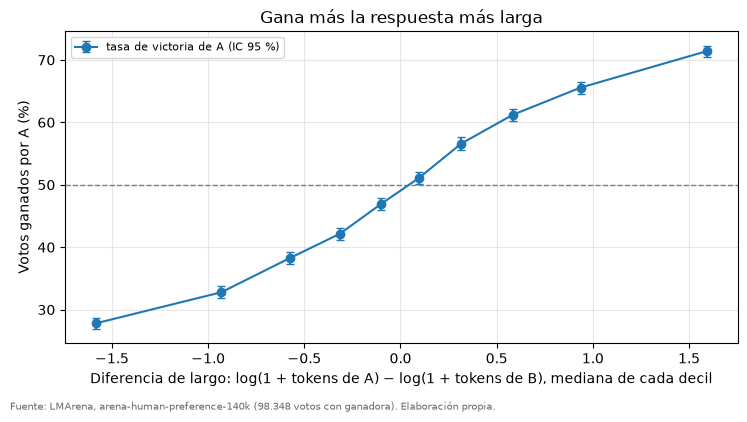

In [12]:
from arena.env import PROJECT_ROOT
from arena.plots import plot_tasa_por_tramos

FIG = PROJECT_ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FUENTE = "Fuente: LMArena, arena-human-preference-140k (98.348 votos con ganadora). Elaboración propia."

fig1 = plot_tasa_por_tramos(
    {"tasa de victoria de A (IC 95 %)": tramos_largo},
    "Gana más la respuesta más larga",
    "Diferencia de largo: log(1 + tokens de A) − log(1 + tokens de B), mediana de cada decil",
    "Votos ganados por A (%)",
    FUENTE,
)
fig1.savefig(FIG / "f4_largo_tasa.png", dpi=150)
fig1

*Interpretación:* la respuesta más larga gana el 61,8 % de las veces (IC 95 % de 61,5 % a 62,1 %, sobre 98.097 votos en que el largo difiere). La tasa sube de forma pareja con la diferencia de largo: cuando A es mucho más corta que B gana el 27,8 % de las veces, y cuando es mucho más larga, el 71,4 %. En el centro, cuando las dos tienen el mismo largo, la tasa es cercana a 50 %. También hay una diferencia chica de posición: A gana el 49,4 % de los votos con ganadora (48.563 de 98.348), así que B lleva una pequeña ventaja.

### 3.2 Formato de la respuesta, y qué pasa al fijar el largo
**Qué hacemos:** repetir la mirada con el formato (encabezados, listas y negritas), pero separando los votos en tres grupos según la diferencia de largo.
**Por qué:** las respuestas con más formato suelen ser también más largas, así que mirar el formato solo mezcla los dos efectos. Dentro de cada grupo el largo es parecido, y se puede ver si el formato aporta algo más.

In [13]:
import numpy as np

d["grupo_largo"] = pd.qcut(d["dif_tokens_log"], 3, labels=["A bastante más corta", "largo parecido", "A bastante más larga"])
print("correlación entre diferencia de largo y de formato:", round(d["dif_tokens_log"].corr(d["dif_formato_log"]), 3))

tramos_formato = {g: tasa_por_tramos(sub, "dif_formato_log", 6) for g, sub in d.groupby("grupo_largo", observed=True)}
todos_formato = tasa_por_tramos(d, "dif_formato_log", 8)
todos_formato.assign(tasa_pct=(todos_formato["tasa"] * 100).round(1))[["centro", "n", "tasa_pct"]].round(2)

correlación entre diferencia de largo y de formato: 0.723


,centro,n,tasa_pct
dif_formato_log,,,
"(-7.373, -1.692]",-2.48,12304,33.5
"(-1.692, -0.793]",-1.16,12283,38.9
"(-0.793, -0.288]",-0.54,12307,42.7
"(-0.288, 0.0]",0.00,16437,48.3
"(0.0, 0.296]",0.15,8139,50.8
"(0.296, 0.796]",0.54,12292,55.8
"(0.796, 1.705]",1.19,12325,60.7
"(1.705, 6.732]",2.52,12261,65.1


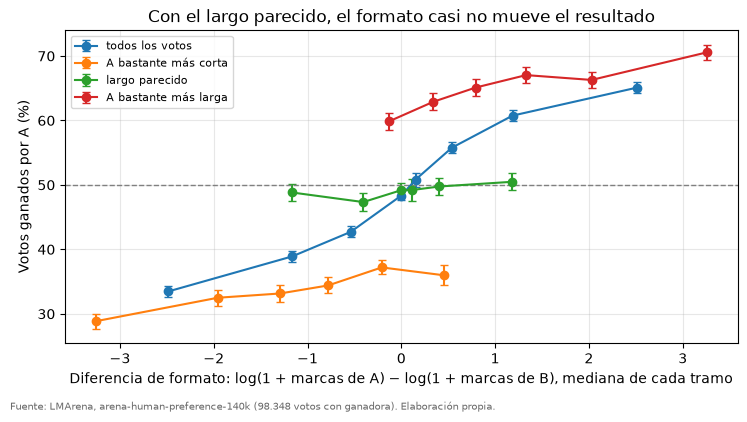

In [14]:
fig2 = plot_tasa_por_tramos(
    {"todos los votos": todos_formato, **tramos_formato},
    "Con el largo parecido, el formato casi no mueve el resultado",
    "Diferencia de formato: log(1 + marcas de A) − log(1 + marcas de B), mediana de cada tramo",
    "Votos ganados por A (%)",
    FUENTE,
)
fig2.savefig(FIG / "f4_formato_por_largo.png", dpi=150)
fig2

*Interpretación:* mirando todos los votos juntos, el formato parece pesar mucho: la tasa de A sube de 33,5 % a 65,1 % entre los tramos extremos, y la respuesta con más formato gana el 59,5 % de las veces. Pero formato y largo van juntos: la correlación entre las dos diferencias es de 0,72. Al separar los votos por diferencia de largo, la relación se aplana donde más se puede ver: cuando las dos respuestas tienen un largo parecido, la tasa se queda entre 47 % y 51 % sin importar cuánto más formato tenga A. En los grupos donde A es bastante más corta o más larga todavía queda una pendiente, pero cada uno de esos grupos cubre un rango amplio de largos, y parte de esa pendiente es largo que no quedó del todo fijo. El modelo de la sección siguiente usa el largo como variable continua para evitarlo.

### 3.3 Largo y formato juntos
**Qué hacemos:** ajustar tres regresiones logísticas con las diferencias estandarizadas: solo largo, solo formato y ambos.
**Por qué:** la regresión da, en una sola cifra por variable, cuánto se asocia cada una con ganar cuando la otra se mantiene fija. Los coeficientes están en log-odds por desviación estándar, así que se comparan entre sí.

In [15]:
from arena.analisis import modelos_p1

modelos = modelos_p1(d)
modelos[["n", "coef", "error_est", "ic_bajo", "ic_alto", "odds", "p"]].round(4)

n    coef  error_est  ic_bajo  \
modelo             variable                                             
solo longitud      dif_tokens_log   98348  0.5828     0.0075   0.5681   
solo formato       dif_formato_log  98348  0.4218     0.0069   0.4083   
longitud y formato dif_tokens_log   98348  0.5515     0.0105   0.5309   
                   dif_formato_log  98348  0.0411     0.0098   0.0219   

                                    ic_alto    odds    p  
modelo             variable                               
solo longitud      dif_tokens_log    0.5975  1.7910  0.0  
solo formato       dif_formato_log   0.4353  1.5247  0.0  
longitud y formato dif_tokens_log    0.5722  1.7359  0.0  
                   dif_formato_log   0.0604  1.0420  0.0

*Interpretación:* por separado, las dos variables se asocian con ganar. Una desviación estándar más de largo (una respuesta unas 2,7 veces más larga que la otra) multiplica las odds de ganar por 1,79, y una más de formato por 1,52. Juntas la historia cambia: el coeficiente del largo casi no se mueve (de 0,58 a 0,55, odds 1,74) y el del formato cae de 0,42 a 0,04 (odds 1,04, IC 95 % de 0,022 a 0,060). Sigue siendo distinto de cero, pero unas 13 veces menor que el del largo. Los p aparecen como 0,0 porque son menores que 0,00005. En este modelo, casi todo lo que parecía efecto del formato es en realidad largo.

### 3.4 ¿Se sostiene en otros subconjuntos?
**Qué hacemos:** repetir el modelo con largo y formato en subconjuntos distintos de votos.
**Por qué:** un resultado que solo aparece en el conjunto completo es frágil. Se revisan tres cosas: que no dependa de las sesiones con muchos votos, que no dependa del idioma y que valga también para código.

- **Primer voto de cada sesión:** las filas de una misma sesión no son independientes; con un solo voto por sesión esa dependencia desaparece.
- **Inglés y otros idiomas:** el 52,5 % de los votos es en inglés.
- **Con y sin código:** el formato puede importar distinto cuando la respuesta es código.

In [16]:
from arena.analisis import coeficientes_por_subconjunto

subconjuntos = {
    "todos los votos": pd.Series(True, index=d.index),
    "primer voto de la sesión": d["evaluation_order"] == 1,
    "inglés": d["language"] == "en",
    "otros idiomas": d["language"] != "en",
    "con código": d["is_code"],
    "sin código": ~d["is_code"],
}
robustez = coeficientes_por_subconjunto(d, subconjuntos)
robustez[["n", "coef", "ic_bajo", "ic_alto"]].round(3)

n   coef  ic_bajo  ic_alto
subconjunto              variable                                       
todos los votos          dif_tokens_log   98348  0.552    0.531    0.572
                         dif_formato_log  98348  0.041    0.022    0.060
primer voto de la sesión dif_tokens_log   79073  0.566    0.543    0.589
                         dif_formato_log  79073  0.049    0.027    0.071
inglés                   dif_tokens_log   51664  0.521    0.493    0.549
                         dif_formato_log  51664  0.018   -0.008    0.044
otros idiomas            dif_tokens_log   46684  0.584    0.553    0.615
                         dif_formato_log  46684  0.072    0.044    0.101
con código               dif_tokens_log   28287  0.574    0.538    0.610
                         dif_formato_log  28287 -0.060   -0.093   -0.027
sin código               dif_tokens_log   70061  0.535    0.510    0.560
                         dif_formato_log  70061  0.087    0.064    0.111

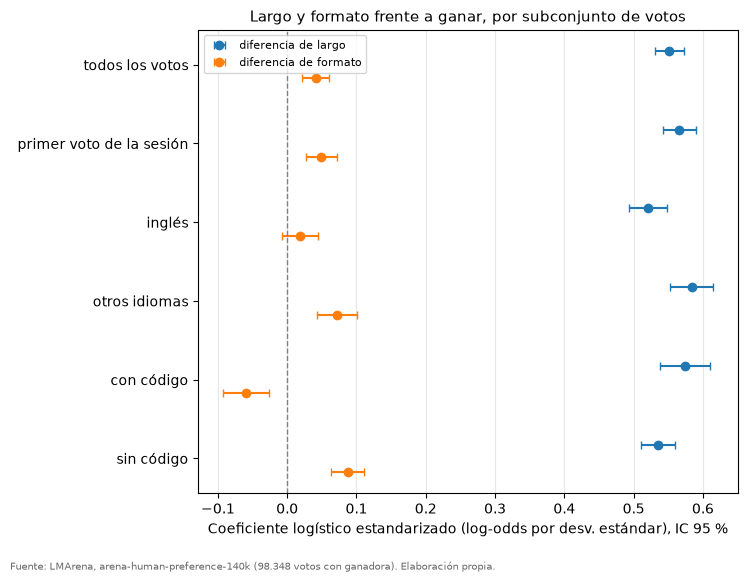

In [17]:
from arena.plots import plot_coeficientes

fig3 = plot_coeficientes(
    robustez,
    "Largo y formato frente a ganar, por subconjunto de votos",
    "Coeficiente logístico estandarizado (log-odds por desv. estándar), IC 95 %",
    FUENTE,
    etiquetas={"dif_tokens_log": "diferencia de largo", "dif_formato_log": "diferencia de formato"},
)
fig3.savefig(FIG / "f4_robustez.png", dpi=150)
fig3

*Interpretación:* el largo mantiene un coeficiente de entre 0,52 y 0,58 en los seis subconjuntos, con intervalos que no incluyen el 0 en ninguno. En el primer voto de cada sesión casi no cambia (0,57), así que la dependencia entre votos de una misma sesión no explica el resultado. El formato es más inestable: es pequeño y positivo en general, no se distingue de cero en inglés (0,018, IC de −0,008 a 0,044), es algo mayor en otros idiomas (0,072) y en los votos sin código (0,087), y es negativo en los votos marcados como código (−0,060). Es decir, cuando la respuesta es código, a igual largo, más listas y negritas se asocian con perder un poco. Con estos datos no podemos explicarlo; queda como pregunta abierta.

### 3.5 Controlando por el modelo de cada lado
**Qué hacemos:** repetir la regresión agregando una columna por modelo de lenguaje (+1 si juega de A, −1 si juega de B). Es un modelo de Bradley-Terry con control de estilo.
**Por qué:** hasta acá no se consideró qué modelos se enfrentan. Si los modelos más fuertes también escriben más largo, parte del efecto del largo sería en realidad la fuerza del modelo. Con las columnas de modelo, el efecto del largo se mide dentro de cada par.

In [18]:
from arena.analisis import efecto_con_modelos

con_modelo = efecto_con_modelos(d)
con_modelo[["n", "n_modelos", "coef", "ic_bajo", "ic_alto", "odds"]].round(3)

n  n_modelos   coef  ic_bajo  \
ajuste                variable                                            
sin control de modelo dif_tokens_log   98348         52  0.552    0.531   
                      dif_formato_log  98348         52  0.041    0.022   
con control de modelo dif_tokens_log   98348         52  0.445    0.421   
                      dif_formato_log  98348         52  0.110    0.087   

                                       ic_alto   odds  
ajuste                variable                         
sin control de modelo dif_tokens_log     0.572  1.736  
                      dif_formato_log    0.060  1.042  
con control de modelo dif_tokens_log     0.468  1.560  
                      dif_formato_log    0.133  1.116

*Interpretación:* al controlar por el modelo de cada lado el coeficiente del largo baja de 0,552 a 0,445 (odds de 1,74 a 1,56), y el del formato sube de 0,041 a 0,110 (odds de 1,04 a 1,12, IC 95 % de 0,087 a 0,133). Hay dos lecturas. La primera: parte del efecto del largo que veíamos antes era fuerza del modelo, porque los modelos que ganan más también tienden a escribir más largo. La segunda: una vez que se compara dentro de cada par de modelos, el formato sí tiene una asociación pequeña pero distinguible con ganar, que antes quedaba tapada. Aun así el largo sigue siendo unas 4 veces mayor que el formato, y el resultado principal no cambia: el largo es la variable más asociada con ganar. El control es parcial, porque no considera el tipo de pregunta ni la calidad del contenido.

## 4. Discusión
**Contra la hipótesis inicial.** El proyecto partió de que la extensión y el formato de una respuesta podrían asociarse con la preferencia humana, además de su contenido. Los resultados lo confirman para el largo, que es la asociación más fuerte y más estable: la respuesta más larga gana el 61,8 % de los votos con ganadora, y el coeficiente se mantiene entre 0,45 y 0,58 según el modelo y el subconjunto. Para el formato la evidencia es más débil: parece grande mirando solo el formato (59,5 %), casi desaparece al controlar el largo (0,04) y queda pequeño al controlar además el modelo (0,11).

**Limitaciones.**
- **No hay control de calidad.** Una respuesta más larga puede ser mejor porque es más completa. El dato no permite separar eso de una preferencia por el largo en sí.
- **El control por modelo es parcial.** No incluimos el tipo de pregunta (`category_tag`) ni el prompt.
- **Solo votos con ganadora.** El 27,5 % de los votos (`tie` y `both_bad`) queda fuera de las tasas, y se concentra donde el largo difiere poco.
- **El formato se mide con conteos.** Son marcas de Markdown (encabezados, listas y negritas), no cómo se ve la respuesta renderizada.
- **Los votos de una misma sesión no son independientes.** Se revisó con el primer voto de cada sesión y el resultado casi no cambia, pero los intervalos del modelo completo son algo optimistas.
- **Estudio observacional.** No se pueden hacer afirmaciones causales.

**Riesgos.** Leer estos resultados como causales y concluir que alargar las respuestas las hace mejores. Si una evaluación por preferencia premia el largo, un modelo puede mejorar su puntaje escribiendo más sin mejorar su contenido (Dubois et al., 2024). Por eso el control de estilo es una práctica recomendada en esta clase de evaluaciones (Li et al., 2024).

**Con las fases anteriores.** F2 dejó pendiente qué hacer con los empates y el control por idioma (P-01). Aquí se revisaron: los empates se concentran cuando el largo difiere poco, y el resultado se sostiene en inglés y en otros idiomas. F3 dejó el pipeline reproducible; que el notebook parta de `pasos_f3()` y no de un archivo guardado es lo que permite repetir todo el análisis desde el dato crudo.

## 5. Conclusiones
1. **El largo es lo más asociado con ganar.** La respuesta más larga gana el 61,8 % de los votos con ganadora, y la tasa de A sube de 27,8 % a 71,4 % según cuánto más larga sea. El resultado se sostiene en los seis subconjuntos revisados.
2. **El formato aporta poco por sí solo.** Casi todo lo que parecía efecto del formato se explica por el largo. Controlando largo y modelo queda una asociación pequeña (odds de 1,12 por desviación estándar).
3. **Aprendizajes técnicos.** Partir de `pasos_f3()` en vez de un archivo guardado hace el análisis repetible de punta a punta. Probar las funciones de análisis con datos simulados con coeficientes conocidos permitió confiar en una regresión escrita solo con NumPy. Y revisar subconjuntos y el control por modelo cambió la lectura del formato, algo que el análisis simple no mostraba.
4. **Mejoras propuestas, basadas en lo observado.** Agregar el tipo de pregunta (`category_tag`) como control; comparar el modelo con y sin votos sin ganadora; y probar una medida de formato más cercana a lo que ve la persona (por ejemplo, la proporción de líneas con formato). Todo esto cabe en `arena.analisis` sin cambiar el pipeline.

## 6. Relación con las fases
| Fase | Aporte al resultado | Evidencia en el repositorio |
|---|---|---|
| F1 | Definió P1 y dejó el entorno reproducible. | `F1/F1_Definicion.ipynb`, `requirements.txt`, `Makefile` |
| F2 | Cargó, exploró, limpió y validó el dato. | `F2/`, `arena.preprocessing`, `arena.validation` |
| F3 | Reescribió el pipeline como clases, lo probó y midió su eficiencia. | `F3/`, `arena.transformadores`, `tests/` |
| F4 | Responde P1 con tasas, regresiones y tres gráficos. | este notebook, `arena.analisis`, `arena.plots` |

## Referencias
- Bradley, R. A., & Terry, M. E. (1952). Rank analysis of incomplete block designs: I. The method of paired comparisons. *Biometrika, 39*(3/4), 324–345. https://doi.org/10.2307/2334029
- Chiang, W.-L., Zheng, L., Sheng, Y., et al. (2024). Chatbot Arena: An open platform for evaluating LLMs by human preference. *Proceedings of the 41st International Conference on Machine Learning, 235*, 8359–8388. https://proceedings.mlr.press/v235/chiang24b.html
- Dubois, Y., Galambosi, B., Liang, P., & Hashimoto, T. B. (2024). *Length-controlled AlpacaEval: A simple way to debias automatic evaluators* (arXiv:2404.04475). https://doi.org/10.48550/arXiv.2404.04475
- Li, T., Angelopoulos, A., & Chiang, W.-L. (2024). *Does style matter? Disentangling style and substance in Chatbot Arena*. LMSYS. https://lmsys.org/blog/2024-08-28-style-control/
- LMArena. (2025). *Arena-human-preference-140k* [Conjunto de datos]. Hugging Face. https://huggingface.co/datasets/lmarena-ai/arena-human-preference-140k
- Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953
- Wu, M., & Aji, A. F. (2025). Style over substance: Evaluation biases for large language models. *Proceedings of the 31st International Conference on Computational Linguistics*, 297–312. https://aclanthology.org/2025.coling-main.21/